# 05 · Sample the 2×2 policy map with QAOA

## Question

Can QAOA sample the same optimal policy map found classically?

## Concept

**Physics / quantum view.** QAOA is the Quantum Approximate Optimization Algorithm. Its cost Hamiltonian assigns an energy to each candidate, which determines the phase it acquires. Its mixer Hamiltonian generates rotations that redistribute amplitudes between candidates. A statevector records those complex amplitudes, while a shot yields one measured string.

The cost Hamiltonian $H_C$ from Notebook 04 assigns each bit string its energy up to a constant. Starting in an equal superposition, apply one cost layer $e^{-i\gamma H_C}$ and one mixer layer $e^{-i\beta\sum_i X_i}$. This is QAOA with $p=1$. The cost layer changes phases and the mixer converts phase differences into changes in measurement probabilities.

A classical grid search selects variational angles by minimizing ideal statevector energy. Aer then measures the chosen circuit repeatedly. Each shot produces one string. The offset is included in reported energies and would contribute only a global phase to the circuit.

The default uses the illustrative scores from Notebooks 01, 03, and 04. To repeat with measured scores, run the offline command shown in Notebook 02, set the repo-relative path to its generated JSON, and compare against exact enumeration for that instance.

## Check / exercise

Predict which string is optimal for the illustrative matrix. Before sampling, predict the feasible and optimal probabilities for uniform random bits.

## Worked example · establish the exact baseline

In [1]:
from itertools import product
import json
from pathlib import Path

import numpy as np
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator

instance_path = None  # Optional repo-relative path to a generated instance.json
J = np.array([[-1.0, -3.0], [-2.5, -1.0]])
A = 5.0
source = "illustrative scores in arbitrary units"
if instance_path is not None:
    cwd = Path.cwd()
    root = next(path for path in (cwd, *cwd.parents)
                if (path / "ie" / "run_synthesis_offline.py").is_file())
    instance = json.loads((root / instance_path).read_text(encoding="utf-8"))
    if instance["schema_version"] != 1 or instance["switch_cost"] != 0:
        raise ValueError("Expected a version 1 IE instance with zero switching cost.")
    J = -np.asarray(instance["cost_matrix"], dtype=float)
    if J.shape != (2, 2) or not np.isfinite(J).all():
        raise ValueError("Expected a finite 2×2 performance matrix.")
    # The absolute-sum bound covers the range of the binary performance term.
    A = float(np.abs(J).sum() + 1)
    source = f"IE-derived scores in {instance['cost_unit']}"

print(f"Qiskit {qiskit.__version__}, Aer {qiskit_aer.__version__}")
print(source, "\n", J)
map_scores = {(a, b): J[0, a] + J[1, b] for a, b in product(range(2), repeat=2)}
best_score = max(map_scores.values())
optimal_maps = {pair for pair, score in map_scores.items() if np.isclose(score, best_score)}
print("Exact optimal maps (policy numbers):",
      [tuple(j + 1 for j in pair) for pair in sorted(optimal_maps)])
print(f"Exact performance: {best_score:.4f}; exact minimization objective: {-best_score:.4f}")

Qiskit 2.6.2, Aer 0.18.4
illustrative scores in arbitrary units 
 [[-1.  -3. ]
 [-2.5 -1. ]]
Exact optimal maps (policy numbers): [(1, 2)]
Exact performance: -2.0000; exact minimization objective: 2.0000


### Verify the input Hamiltonian

Reapply the coefficient formulas from Notebook 04 and check every energy before optimizing the circuit. Basis labels are reversed here to match the teaching order $q_{11},q_{12},q_{21},q_{22}$.

In [2]:
linear = -J.ravel() - A
fields = -linear / 2
couplings = {(0, 1): A / 2, (2, 3): A / 2}
offset = 2 * A + linear.sum() / 2 + sum(couplings.values())
for (i, j), coupling in couplings.items():
    fields[i] -= coupling
    fields[j] -= coupling

H_C = SparsePauliOp.from_sparse_list(
    [("Z", [i], h) for i, h in enumerate(fields)]
    + [("ZZ", [i, j], value) for (i, j), value in couplings.items()],
    num_qubits=4,
)
energies = H_C.to_matrix().diagonal().real + offset
labels = [f"{i:04b}" for i in range(16)]
bits = np.array([list(map(int, label[::-1])) for label in labels]).reshape(16, 2, 2)
row_counts = bits.sum(axis=2)
objectives = -(bits * J).sum(axis=(1, 2))
feasible = (row_counts == 1).all(axis=1)
optimal = feasible & np.isclose(objectives, -best_score)
np.testing.assert_allclose(energies, objectives + A * ((row_counts - 1)**2).sum(axis=1),
                           atol=1e-12)
assert np.array_equal(np.isclose(energies, energies.min()), optimal)

### Choose angles and sample

Each $Z$ field becomes an RZ rotation; each $ZZ$ coupling becomes an RZZ rotation. The mixer uses one RX rotation per qubit. The factor of two comes from the half-angle convention for these gates.

In [3]:
def circuit_at(gamma, beta):
    circuit = QuantumCircuit(4)
    circuit.h(range(4))
    for i, h in enumerate(fields):
        circuit.rz(2 * gamma * h, i)
    for (i, j), value in couplings.items():
        circuit.rzz(2 * gamma * value, i, j)
    circuit.rx(2 * beta, range(4))
    return circuit

def expected_energy(gamma, beta):
    probabilities = Statevector.from_instruction(circuit_at(gamma, beta)).probabilities()
    return float(probabilities @ energies)

angle_scale = max(1.0, float(np.abs(J).max())) if instance_path is not None else 1.0
grid = product(np.linspace(0, 2 * np.pi / angle_scale, 48, endpoint=False),
               np.linspace(0, np.pi, 32, endpoint=False))
ideal_mean, gamma, beta = min((expected_energy(g, b), g, b) for g, b in grid)
circuit = circuit_at(gamma, beta)
measured = circuit.copy()
measured.measure_all()
backend = AerSimulator()
seed = 42
shots = 4096
compiled = transpile(measured, backend, seed_transpiler=seed)
counts = backend.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()
assert sum(counts.values()) == shots
probabilities = np.array([counts.get(label, 0) / shots for label in labels])
print(circuit.draw(output="text", fold=-1))

     ┌───┐┌─────────────┐             ┌──────────┐
q_0: ┤ H ├┤ Rz(-13π/24) ├─■───────────┤ Rx(3π/2) ├
     ├───┤└┬────────────┤ │ZZ(65π/24) ├──────────┤
q_1: ┤ H ├─┤ Rz(-13π/8) ├─■───────────┤ Rx(3π/2) ├
     ├───┤┌┴────────────┤             ├──────────┤
q_2: ┤ H ├┤ Rz(-65π/48) ├─■───────────┤ Rx(3π/2) ├
     ├───┤├─────────────┤ │ZZ(65π/24) ├──────────┤
q_3: ┤ H ├┤ Rz(-13π/24) ├─■───────────┤ Rx(3π/2) ├
     └───┘└─────────────┘             └──────────┘


## Result

**Why it matters here.** Circuit depth counts sequential layers after parallel operations are grouped. Transpilation compiles a circuit to a backend?s supported gates and connectivity, so its resulting depth can differ from logical depth.

The mean penalized energy uses all shots. The mean unpenalized objective below uses only feasible shots, because only those strings encode policy maps.

Angles (radians): gamma=1.701696, beta=2.356194
Backend: aer_simulator, shots=4096, seed=42, grid=48×32
Feasible probability: 90.92%
Optimal probability: 59.77%
Best sampled map: (1, 2); objective=2.0000
Mean feasible sampled objective: 2.6599
Mean penalized energy: 3.2546 (shots), 3.3145 (ideal)
Logical depth: 4; transpiled depth with measurement: 4
Logical gates: {'h': 4, 'rz': 4, 'rx': 4, 'rzz': 2}
Transpiled operations: {'u3': 6, 'measure': 4, 'u2': 2, 'cry': 1, 'rxx': 1, 'barrier': 1}


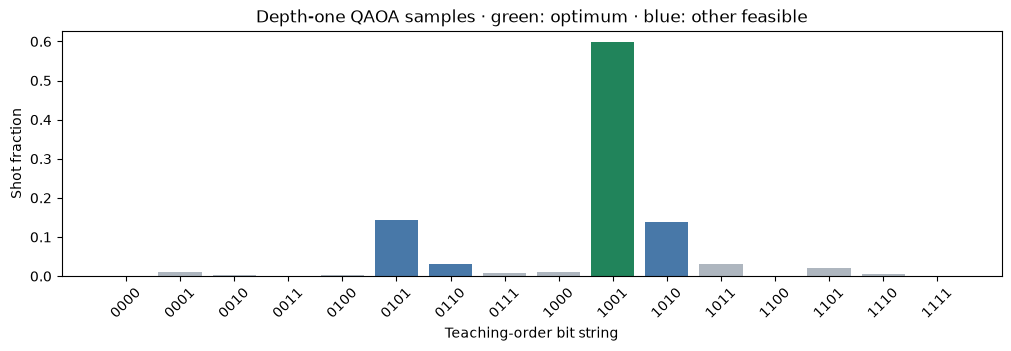

In [4]:
import matplotlib.pyplot as plt

sampled_feasible = np.flatnonzero(feasible & (probabilities > 0))
print(f"Angles (radians): gamma={gamma:.6f}, beta={beta:.6f}")
print(f"Backend: {backend.name}, shots={shots}, seed={seed}, grid=48×32")
print(f"Feasible probability: {probabilities @ feasible:.2%}")
print(f"Optimal probability: {probabilities @ optimal:.2%}")
if sampled_feasible.size:
    best = min(sampled_feasible, key=lambda i: objectives[i])
    decoded = tuple(int(policy) + 1 for policy in np.argmax(bits[best], axis=1))
    feasible_mean = (probabilities[feasible] @ objectives[feasible]) / probabilities[feasible].sum()
    print(f"Best sampled map: {decoded}; objective={objectives[best]:.4f}")
    print(f"Mean feasible sampled objective: {feasible_mean:.4f}")
else:
    print("No feasible map sampled.")
print(f"Mean penalized energy: {probabilities @ energies:.4f} (shots), {ideal_mean:.4f} (ideal)")
print(f"Logical depth: {circuit.depth()}; transpiled depth with measurement: {compiled.depth()}")
print("Logical gates:", dict(circuit.count_ops()))
print("Transpiled operations:", dict(compiled.count_ops()))

order = sorted(range(16), key=lambda i: labels[i][::-1])
colors = ["#21845b" if optimal[i] else "#4878a8" if feasible[i] else "#aeb6bf" for i in order]
fig, ax = plt.subplots(figsize=(10, 3.4), layout="constrained")
ax.bar([labels[i][::-1] for i in order], probabilities[order], color=colors)
ax.tick_params(axis="x", labelrotation=45)
ax.set(xlabel="Teaching-order bit string", ylabel="Shot fraction",
       title="Depth-one QAOA samples · green: optimum · blue: other feasible")
plt.show()

**Exercise check.** In the illustrative instance the exact optimum is 1001. Uniform random bits give a 4/16 feasible probability and a 1/16 optimal probability. They are simple reference rates for interpreting the histogram. The experiment compares a tiny circuit with exact enumeration and provides no evidence of quantum advantage.

## Takeaway

The complete mapping pipeline works for a tiny instance: policy map → QUBO → Ising → QAOA → sampled solutions.

## Next step

Freeze and verify one reproducible IE-derived instance before comparing policy maps with inter-regime coupling in [Notebook 06](06_coupled_policy_map.ipynb).

### Presentation asset

Reuse the circuit and the histogram highlighting the exact optimum, with the feasible and optimal sampling probabilities beside it.

MkDocs topic for this notebook: `docs/qaoa.md`.